# 03 — Fuel Price Over 27 Years

The price per litre is the richest signal in this dataset. We look at its
nominal evolution 1999-2026 (across the peseta->euro change) and, once the
INE CPI is available, its **real** evolution in constant euros, which
separates genuine fuel-price moves from general inflation.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from galloper import io, cleaning, features, deflate, config, viz

viz.set_style()

df = cleaning.clean(io.load_raw())
df = features.add_trip_features(df)
df = features.flag_price_outliers(df)

# Drop the few price outliers for the price charts (candidate errors).
dfp = df[~df['price_outlier'] & df['price_per_l'].notna()].copy()
print(f"{len(dfp)} fill-ups with usable price")


522 fill-ups with usable price


## 1. Nominal price per litre over time

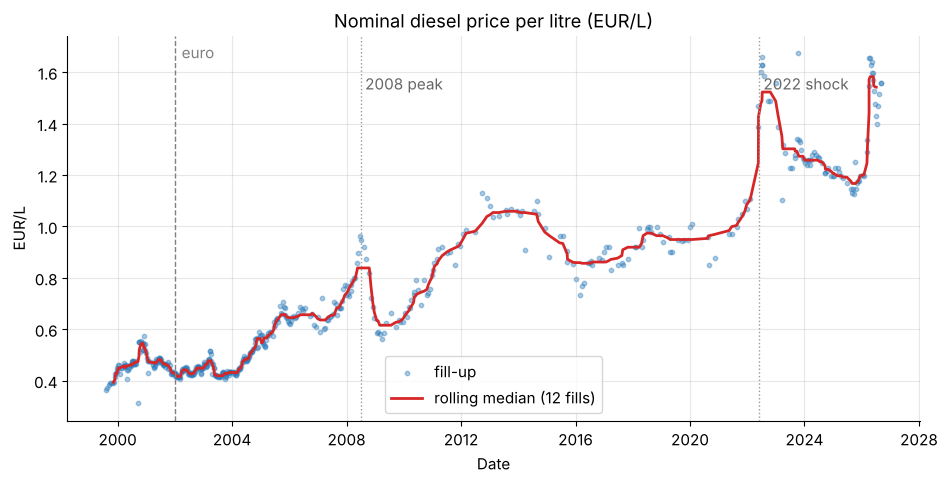

In [2]:
fig, ax = plt.subplots()
ax.scatter(dfp['date'], dfp['price_per_l'], s=10, alpha=0.4,
           color='#2b7bba', label='fill-up')
# Rolling median to show the trend through the noise.
s = dfp.sort_values('date')
ax.plot(s['date'], s['price_per_l'].rolling(12, center=True).median(),
        color='#d62728', lw=2, label='rolling median (12 fills)')
# Context annotations.
ax.axvline(pd.Timestamp('2002-01-01'), ls='--', color='grey', lw=1)
ax.text(pd.Timestamp('2002-02-01'), ax.get_ylim()[1]*0.95, ' euro', color='grey')
for yr, lbl in [('2008-07-01', '2008 peak'), ('2022-06-01', '2022 shock')]:
    ax.axvline(pd.Timestamp(yr), ls=':', color='#999', lw=1)
    ax.text(pd.Timestamp(yr), ax.get_ylim()[1]*0.88, ' '+lbl, color='#666')
ax.set_title("Nominal diesel price per litre (EUR/L)")
ax.set_xlabel("Date"); ax.set_ylabel("EUR/L"); ax.legend()
viz.savefig(fig, "03_price_nominal"); plt.show()

## 2. Average price per year (nominal)

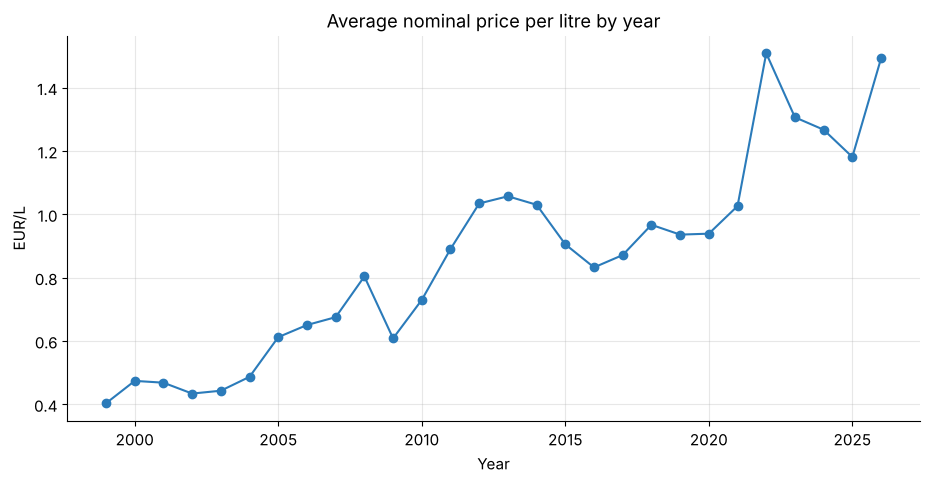

In [3]:
yearly = features.yearly_summary(df)
fig, ax = plt.subplots()
ax.plot(yearly['year'].astype(int), yearly['avg_price_per_l'],
        marker='o', color='#2b7bba')
ax.set_title("Average nominal price per litre by year")
ax.set_xlabel("Year"); ax.set_ylabel("EUR/L")
viz.savefig(fig, "03_price_yearly_avg"); plt.show()

## 3. Real vs nominal price (needs INE CPI)

In [4]:
# Real (inflation-adjusted) prices require the INE CPI file.
# Download table 50902 (Indice general, data type 'Indice', monthly, from
# 1999) and save it as data/raw/ine_ipc.csv. If absent, we skip the real
# series and keep the nominal analysis.
IPC_PATH = config.DATA_RAW / "ine_ipc.csv"
HAS_IPC = IPC_PATH.exists()

if HAS_IPC:
    ipc = deflate.load_ipc(IPC_PATH)
    dfp = deflate.attach_real_prices(dfp, ipc, ref_period="2026-01")
    print("CPI loaded:", ipc['date'].min().date(), "->", ipc['date'].max().date())
else:
    print("ine_ipc.csv not found - showing nominal prices only.")


ine_ipc.csv not found - showing nominal prices only.


In [5]:
if HAS_IPC:
    s = dfp.sort_values('date')
    fig, ax = plt.subplots()
    ax.plot(s['date'], s['price_per_l'].rolling(12, center=True).median(),
            color='#999', lw=2, label='nominal')
    ax.plot(s['date'], s['price_per_l_real'].rolling(12, center=True).median(),
            color='#d62728', lw=2, label='real (2026 EUR)')
    ax.set_title("Diesel price: nominal vs real (constant 2026 EUR)")
    ax.set_xlabel("Date"); ax.set_ylabel("EUR/L"); ax.legend()
    viz.savefig(fig, "03_price_real_vs_nominal"); plt.show()
else:
    print("Skipped: provide data/raw/ine_ipc.csv to see the real series.")

Skipped: provide data/raw/ine_ipc.csv to see the real series.


### Interpretation hook

Where the **real** line is flat but the nominal line rises, the increase was
just general inflation. Where the real line itself climbs (e.g. 2008, 2022),
diesel got genuinely more expensive relative to everything else. Fill in the
read once the CPI series is loaded.

## 4. Cost of driving: EUR per 100 km over time

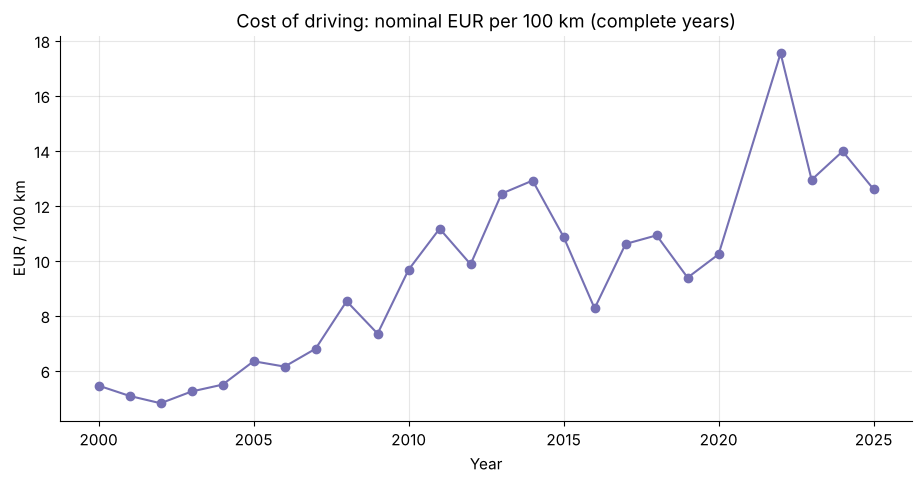

In [6]:
full = yearly[yearly['is_complete']]
fig, ax = plt.subplots()
ax.plot(full['year'].astype(int), full['eur_per_100km'],
        marker='o', color='#7570b3')
ax.set_title("Cost of driving: nominal EUR per 100 km (complete years)")
ax.set_xlabel("Year"); ax.set_ylabel("EUR / 100 km")
viz.savefig(fig, "03_eur_per_100km"); plt.show()